SPLIT=test  data=FRESH 5000pts (seed=13423)  window=[100:200]  device=cuda:1
thresholds=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]
computing ONLY: ['ideal', 'ctx', 'twocell', 'twocell_comb']   (W* logits needed: False)

  thr=0.10  twocell=2.5636  twocell_comb=2.6064  alp=2.5693  ialp=2.4664
  thr=0.20  twocell=2.5692  twocell_comb=2.6725  alp=2.5881  ialp=2.4813
  thr=0.30  twocell=2.5017  twocell_comb=2.6110  alp=2.5263  ialp=2.4302
  thr=0.40  twocell=2.3882  twocell_comb=2.4888  alp=2.4140  ialp=2.3311
  thr=0.50  twocell=2.2415  twocell_comb=2.3225  alp=2.2632  ialp=2.1906
  thr=0.60  twocell=2.0566  twocell_comb=2.1240  alp=2.0772  ialp=2.0109
  thr=0.70  twocell=1.8277  twocell_comb=1.8773  alp=1.8468  ialp=1.7858
  thr=0.80  twocell=1.5541  twocell_comb=1.5912  alp=1.5697  ialp=1.5125
  thr=0.90  twocell=1.2147  twocell_comb=1.2380  alp=1.2313  ialp=1.1771


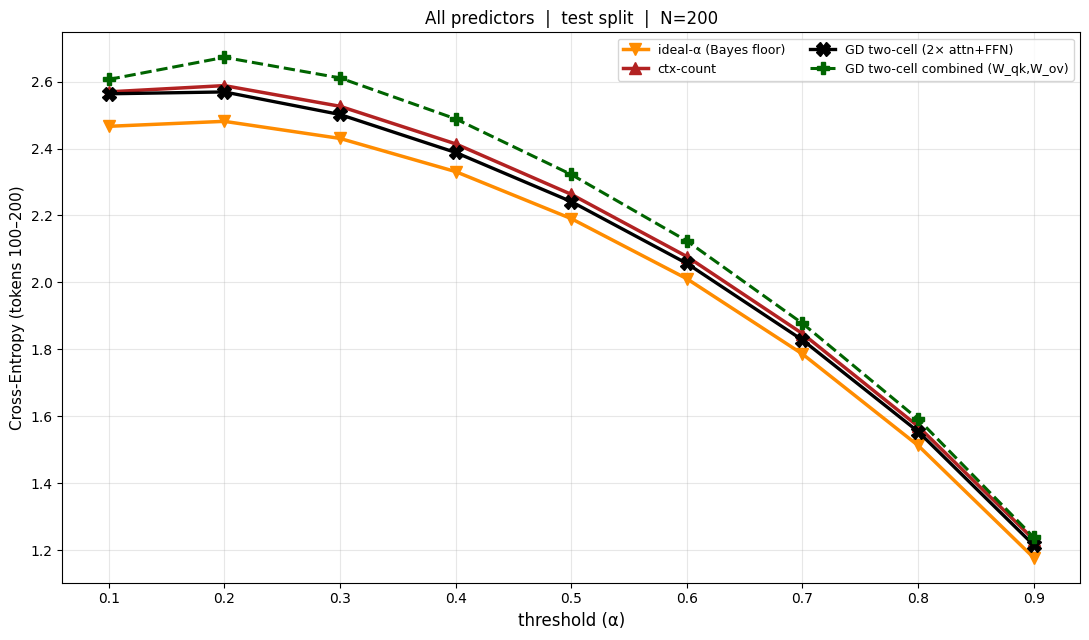

Saved → models/ce_all_test.png

α          ideal-α    ctx-count           GD           GD
0.1         2.4664       2.5693       2.5636       2.6064
0.2         2.4813       2.5881       2.5692       2.6725
0.3         2.4302       2.5263       2.5017       2.6110
0.4         2.3311       2.4140       2.3882       2.4888
0.5         2.1906       2.2632       2.2415       2.3225
0.6         2.0109       2.0772       2.0566       2.1240
0.7         1.7858       1.8468       1.8277       1.8773
0.8         1.5125       1.5697       1.5541       1.5912
0.9         1.1771       1.2313       1.2147       1.2380


In [2]:
# ══ MERGED: settings + lazy compute + plot (single self-contained cell) ════════
# Computes ONLY the curves whose SHOW flag is True, and ONLY for the chosen SPLIT.
# (No more "run cell 1, wait for every model, lose it on disconnect" — toggle a
#  curve on, run THIS cell, and just that curve's data is computed + plotted.)
# Edit SPLIT / SHOW (and, rarely, the paths) below; everything else is definitions.

SPLIT = 'test'                                          # 'test' or 'train'
# Each flag toggles one curve in the plot below. What each curve is:
#   -- analytic references --
#   ideal : ideal-alpha -- Bayes-optimal floor that KNOWS the true transition table
#           (lowest possible CE; NOT reachable from context alone)
#   ctx   : ctx-count   -- the empirical in-context successor frequencies
#           (what a perfect count-reader of the context achieves)
#   -- GD-trained networks --
#   gd           : plain softmax, SEPARATE Wq,Wk,Wv,Wo, NO FFN        (folder 6 train.py)
#   gd_comb      : plain softmax, COMBINED W_qk,W_ov,  NO FFN         (folder 7 train_combined.py)
#   mlp          : SEPARATE attn + ONE FFN before readout            (folder 6 train_with_mlp.py)
#   twocell      : SEPARATE attn + FFN after BOTH layers (two cells) (folder 8 train_two_cell.py)
#   twocell_comb : COMBINED W_qk,W_ov + FFN after both layers        (folder 8 train_two_cell_combined.py)
#   -- hand-constructed predictors (NO training) --
#   wstar    : hand-built W* induction circuit, softmax at fixed temperature WS_SIGMA
#   wbetter  : same W*, but per-alpha temperature + noise-bias (better-tuned readout)
#   l1       : W* read out as (freq+bias)/sum  (divide-by-sum / "L1" head), best-fit floors
#   freeze   : GD model, readout PINNED to W* + a learned noise-floor bias (folder 6)
#   ffn_log1 : hand FFN x1 -- last FFN = log(count+floor); softmax then recovers ctx-count
#   ffn_log2 : hand FFN x2 -- mid FFN = identity + last = log  (identical to ffn_log1)
#   ffn_relu_log : SAME log readout, but the log is a ReLU piecewise-linear approx (hand-set weights, K knots)

SHOW  = dict(
    ideal=True, ctx=True,                              # analytic: Bayes floor / count predictor
    gd=False, gd_comb=False,                            # softmax, no-FFN:  separate / combined
    mlp=False,                                          # separate attn + 1 FFN
    twocell=True, twocell_comb=True,                  # 2-FFN two-cell:   separate / combined
    wstar=False, wbetter=False, l1=False, freeze=False, # hand-built W* readouts
    ffn_log1=False, ffn_log2=False,                     # hand log-readout FFN  (x1 / x2 with mid=identity)
    ffn_relu_log=False,                                 # the log readout built ONLY from ReLU (hand, K=RELU_LOG_K)
    ffn_gelu_log=False,                                 # the log readout built with GELU (model's activation; gain g=GELU_LOG_GAIN)
    count_bayes=False,                                  # OPTIMAL count-domain construction (genuine, scalable): reaches ctx-count
)

# ── FRESH-DATA option ─────────────────────────────────────────────────────────
# USE_FRESH=True → generate brand-new random sequences (SAME Markov-noise distribution as
# dataset/*.pt) on the fly instead of loading the saved split, using N_POINTS sequences.
USE_FRESH = True          # True → fresh generated points;  False → load dataset/<split>/data_x_{thr}.pt
N_POINTS  = 5000           # number of fresh sequences to evaluate the curves on (only if USE_FRESH=True)
FRESH_SEED = 13423         # base RNG seed (reproducible per split/α). Set None for a new draw every run.

# ── SETTINGS (two-cell model + full comparison curves) ─────────────────────────
# Models live in TWO places:
#   MODELS_DIR_2CELL  → this folder's models/  (two-cell, model_mlp_x_{thr}.pth)
#   MODELS_DIR_6      → folder 6's models/      (gd softmax, minimal-MLP, freeze)
# Dataset is the SAME for all (folder 6), so every CE is directly comparable.
DATA_DIR         = '/home/hariguru/ashutosh/ICL/6. understanding what gradient descent is firuring out/dataset'
MODELS_DIR_2CELL = 'models'
MODELS_DIR_6     = '/home/hariguru/ashutosh/ICL/6. understanding what gradient descent is firuring out/models'
MODELS_DIR_7     = '/home/hariguru/ashutosh/ICL/7. unique_Wqk_Wok_test.ipynb/models'  # combined softmax (no FFN)
MODELS_DIR       = MODELS_DIR_2CELL          # where ce_all_*.png is written
DEVICE           = 'cuda:1'

N_SEQS      = 200          # sequences per split used for CE evaluation
TOKEN_START = 100          # CE on tokens 100–200 (last half, seq_len=200)
TOKEN_END   = 200
WS_SIGMA    = 5.5          # temperature on W* logits
ATTN_DIM    = 220          # fallback if a checkpoint has no metrics json
FREEZE_EPS  = 1e-6
RELU_LOG_K  = 7            # knots for the hand-built ReLU approximation of log (6 ReLU units/coord; fits H=128)
GELU_LOG_GAIN = 200.0      # input gain for the GELU hinge: (a/g)*GELU(g*(c-t)) -> a*ReLU(c-t) as g grows

# W*-better per-α params (σ, noise-bias) and L1-head floor (b_sig, b_noise)
SIG_LIST = [3.0, 3.0, 4.0, 4.5, 5.0, 5.0, 6.0, 6.0, 6.0]
BN_LIST  = [3.0, 2.0, 2.0, 1.5, 1.5, 1.0, 1.0, 0.5, -0.5]
L1_PAR   = {0.1:(1e-2,3e-1), 0.2:(1e-2,3e-1), 0.3:(1e-2,3e-1),
            0.4:(3e-3,1e-1), 0.5:(3e-3,1e-1), 0.6:(3e-3,1e-1),
            0.7:(1e-3,3e-2), 0.8:(1e-3,3e-2), 0.9:(1e-3,1e-2)}

# FFN log-readout floors (b_sig, b_noise) per α — GRID-SEARCHED ONCE (offline, _find_floors.py)
# over (b_sig, b_noise) ∈ {1e-4, 3e-4, 1e-3, 3e-3, 1e-2, 3e-2, 1e-1, 3e-1}², CE-argmin at
# N_SEQS=200. Hardcoded so the cell NEVER re-searches (just one CE eval at the optimum).
# Re-tune with:  python _find_floors.py   (rewrites _floors.json; copy values here).
FFN_FLOORS = {
  'log':  {'test':  {0.1:(1e-2,3e-1),0.2:(1e-2,3e-1),0.3:(1e-2,3e-1),0.4:(3e-3,1e-1),0.5:(3e-3,1e-1),0.6:(3e-3,1e-1),0.7:(1e-3,3e-2),0.8:(1e-3,3e-2),0.9:(1e-3,1e-2)},
           'train': {0.1:(1e-2,3e-1),0.2:(1e-2,3e-1),0.3:(1e-2,3e-1),0.4:(3e-3,1e-1),0.5:(3e-3,1e-1),0.6:(3e-3,1e-1),0.7:(1e-3,3e-2),0.8:(1e-3,3e-2),0.9:(1e-3,1e-2)}},
  'relu': {'test':  {0.1:(1e-2,3e-1),0.2:(1e-2,3e-1),0.3:(1e-2,3e-1),0.4:(1e-3,1e-1),0.5:(3e-3,1e-1),0.6:(3e-3,1e-1),0.7:(1e-3,3e-2),0.8:(3e-3,3e-2),0.9:(3e-4,1e-2)},
           'train': {0.1:(1e-2,3e-1),0.2:(1e-2,3e-1),0.3:(1e-2,3e-1),0.4:(3e-3,1e-1),0.5:(3e-3,1e-1),0.6:(3e-3,1e-1),0.7:(1e-3,3e-2),0.8:(1e-3,3e-2),0.9:(3e-4,1e-2)}},
  'gelu': {'test':  {0.1:(1e-2,3e-1),0.2:(1e-2,3e-1),0.3:(1e-2,3e-1),0.4:(1e-3,1e-1),0.5:(3e-3,1e-1),0.6:(3e-3,1e-1),0.7:(1e-3,3e-2),0.8:(1e-3,3e-2),0.9:(3e-4,1e-2)},
           'train': {0.1:(1e-2,3e-1),0.2:(1e-2,3e-1),0.3:(1e-2,3e-1),0.4:(1e-3,1e-1),0.5:(3e-3,1e-1),0.6:(3e-3,1e-1),0.7:(1e-3,3e-2),0.8:(1e-3,3e-2),0.9:(3e-4,1e-2)}},
}
_FFN_FLOOR_DEFAULT = (1e-3, 3e-2)   # fallback if a threshold isn't in the table
# ───────────────────────────────────────────────────────────────────────────────

import os, json as _json
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

device = torch.device(DEVICE)

# ── Base attention block (shared by every model below) ────────────────────────
class ConcatAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)
    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        scores = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores = scores + mask
        attn_out = self.W_o(torch.bmm(F.softmax(scores, dim=-1), V))
        return torch.cat([x, attn_out], dim=-1), scores

# ── (gd / freeze) plain softmax transformer  — folder 6 train.py ──────────────
class DisentangledTransformer(nn.Module):
    def __init__(self, total_vocab, seq_len, attn_dim, bias=False):
        super().__init__()
        self.total_vocab = total_vocab; self.seq_len = seq_len
        self.initial_dim = total_vocab + seq_len
        self.layer1 = ConcatAttentionBlock(self.initial_dim, attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + attn_dim, attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * attn_dim, total_vocab, bias=bias)
    def forward(self, x, return_attn=False):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s, a1 = self.layer1(s, mask)
        s, a2 = self.layer2(s, mask)
        return (self.fc_out(s), [a1, a2]) if return_attn else self.fc_out(s)

# ── (mlp) minimal single-FFN model — folder 6 train_with_mlp.py ───────────────
class DisentangledTransformerMLP(nn.Module):
    def __init__(self, total_vocab, seq_len, attn_dim, mlp_hidden, bias=False, act='gelu'):
        super().__init__()
        self.total_vocab = total_vocab; self.seq_len = seq_len
        self.initial_dim = total_vocab + seq_len
        self.layer1 = ConcatAttentionBlock(self.initial_dim, attn_dim)
        self.layer2 = ConcatAttentionBlock(self.initial_dim + attn_dim, attn_dim)
        D = self.initial_dim + 2 * attn_dim
        self.ff1 = nn.Linear(D, mlp_hidden); self.ff2 = nn.Linear(mlp_hidden, D)
        self.act = nn.GELU() if act == 'gelu' else nn.ReLU()
        self.fc_out = nn.Linear(D, total_vocab, bias=bias)
    def forward(self, x):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s, _ = self.layer1(s, mask); s, _ = self.layer2(s, mask)
        s = s + self.ff2(self.act(self.ff1(s)))
        return self.fc_out(s)

# ── (twocell) THIS folder's model — train_two_cell.py ─────────────────────────
class DisentangledTransformerTwoCell(nn.Module):
    def __init__(self, total_vocab, seq_len, attn_dim, mlp_hidden, bias=False,
                 act='gelu', use_norm_attn=False, use_norm_ffn=False):
        super().__init__()
        self.total_vocab = total_vocab; self.seq_len = seq_len
        self.initial_dim = total_vocab + seq_len
        act_layer = nn.GELU() if act == 'gelu' else nn.ReLU()
        D1 = self.initial_dim + attn_dim
        self.layer1 = ConcatAttentionBlock(self.initial_dim, attn_dim)
        self.ln_attn1 = nn.LayerNorm(self.initial_dim) if use_norm_attn else nn.Identity()
        self.ln_ffn1  = nn.LayerNorm(D1)               if use_norm_ffn  else nn.Identity()
        self.ff1_1 = nn.Linear(D1, mlp_hidden); self.ff1_2 = nn.Linear(mlp_hidden, D1); self.act1 = act_layer
        D2 = D1 + attn_dim
        self.layer2 = ConcatAttentionBlock(D1, attn_dim)
        self.ln_attn2 = nn.LayerNorm(D1) if use_norm_attn else nn.Identity()
        self.ln_ffn2  = nn.LayerNorm(D2) if use_norm_ffn  else nn.Identity()
        self.ff2_1 = nn.Linear(D2, mlp_hidden); self.ff2_2 = nn.Linear(mlp_hidden, D2); self.act2 = act_layer
        self.fc_out = nn.Linear(D2, total_vocab, bias=bias)
    def forward(self, x, return_attn=False):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s, a1 = self.layer1(self.ln_attn1(s), mask)
        s = s + self.ff1_2(self.act1(self.ff1_1(self.ln_ffn1(s))))
        s, a2 = self.layer2(self.ln_attn2(s), mask)
        s = s + self.ff2_2(self.act2(self.ff2_1(self.ln_ffn2(s))))
        logits = self.fc_out(s)
        return (logits, [a1, a2]) if return_attn else logits

# ── (twocell_comb) THIS folder's COMBINED-attention model — train_two_cell_combined.py
class CombinedAttentionBlock(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.input_dim = input_dim; self.output_dim = output_dim
        self.W_qk = nn.Parameter(torch.empty(input_dim, input_dim))
        self.W_ov = nn.Parameter(torch.empty(output_dim, input_dim))
        nn.init.xavier_uniform_(self.W_qk); nn.init.xavier_uniform_(self.W_ov)
    def forward(self, x, mask=None):
        scores = torch.bmm(x @ self.W_qk, x.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: scores = scores + mask
        attn_out = torch.bmm(F.softmax(scores, dim=-1), x @ self.W_ov.t())
        return torch.cat([x, attn_out], dim=-1), scores

class DisentangledTransformerCombined(nn.Module):
    """Combined-attention SOFTMAX model, NO FFN — folder 7 train_combined.py."""
    def __init__(self, total_vocab, seq_len, attn_dim, bias=False):
        super().__init__()
        self.total_vocab = total_vocab; self.seq_len = seq_len
        self.initial_dim = total_vocab + seq_len
        self.layer1 = CombinedAttentionBlock(self.initial_dim, attn_dim)
        self.layer2 = CombinedAttentionBlock(self.initial_dim + attn_dim, attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * attn_dim, total_vocab, bias=bias)
    def forward(self, x, return_attn=False):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s, a1 = self.layer1(s, mask)
        s, a2 = self.layer2(s, mask)
        return (self.fc_out(s), [a1, a2]) if return_attn else self.fc_out(s)

class DisentangledTransformerTwoCellCombined(nn.Module):
    def __init__(self, total_vocab, seq_len, attn_dim, mlp_hidden, bias=False,
                 act='gelu', use_norm_attn=False, use_norm_ffn=False):
        super().__init__()
        self.total_vocab = total_vocab; self.seq_len = seq_len
        self.initial_dim = total_vocab + seq_len
        act_layer = nn.GELU() if act == 'gelu' else nn.ReLU()
        D1 = self.initial_dim + attn_dim
        self.layer1 = CombinedAttentionBlock(self.initial_dim, attn_dim)
        self.ln_attn1 = nn.LayerNorm(self.initial_dim) if use_norm_attn else nn.Identity()
        self.ln_ffn1  = nn.LayerNorm(D1)               if use_norm_ffn  else nn.Identity()
        self.ff1_1 = nn.Linear(D1, mlp_hidden); self.ff1_2 = nn.Linear(mlp_hidden, D1); self.act1 = act_layer
        D2 = D1 + attn_dim
        self.layer2 = CombinedAttentionBlock(D1, attn_dim)
        self.ln_attn2 = nn.LayerNorm(D1) if use_norm_attn else nn.Identity()
        self.ln_ffn2  = nn.LayerNorm(D2) if use_norm_ffn  else nn.Identity()
        self.ff2_1 = nn.Linear(D2, mlp_hidden); self.ff2_2 = nn.Linear(mlp_hidden, D2); self.act2 = act_layer
        self.fc_out = nn.Linear(D2, total_vocab, bias=bias)
    def forward(self, x, return_attn=False):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s, a1 = self.layer1(self.ln_attn1(s), mask)
        s = s + self.ff1_2(self.act1(self.ff1_1(self.ln_ffn1(s))))
        s, a2 = self.layer2(self.ln_attn2(s), mask)
        s = s + self.ff2_2(self.act2(self.ff2_1(self.ln_ffn2(s))))
        logits = self.fc_out(s)
        return (logits, [a1, a2]) if return_attn else logits

# ── (wstar / wbetter / l1) hand-coded perfect induction W* ────────────────────
class _ConcatAttn(nn.Module):
    def __init__(self, input_dim, output_dim):
        super().__init__()
        self.output_dim = output_dim
        self.W_q = nn.Linear(input_dim, output_dim, bias=False)
        self.W_k = nn.Linear(input_dim, output_dim, bias=False)
        self.W_v = nn.Linear(input_dim, output_dim, bias=False)
        self.W_o = nn.Linear(output_dim, output_dim, bias=False)
    def forward(self, x, mask=None):
        Q, K, V = self.W_q(x), self.W_k(x), self.W_v(x)
        s = torch.bmm(Q, K.transpose(1, 2)) / (self.output_dim ** 0.5)
        if mask is not None: s = s + mask
        return torch.cat([x, self.W_o(torch.bmm(F.softmax(s, dim=-1), V))], dim=-1)

class PerfectInductionTransformer(nn.Module):
    def __init__(self, total_vocab, seq_len, vocab_set1):
        super().__init__()
        self.total_vocab = total_vocab; self.seq_len = seq_len; self.vocab_set1 = vocab_set1
        self.initial_dim = total_vocab + seq_len; self.attn_dim = self.initial_dim
        self.layer1 = _ConcatAttn(self.initial_dim, self.attn_dim)
        self.layer2 = _ConcatAttn(self.initial_dim + self.attn_dim, self.attn_dim)
        self.fc_out = nn.Linear(self.initial_dim + 2 * self.attn_dim, total_vocab, bias=False)
        self._set_weights()
    def _set_weights(self):
        V = self.total_vocab; T = self.seq_len; D = self.attn_dim; V_r = self.vocab_set1
        self.layer1.W_q.weight.data = torch.eye(D) * (D ** 0.5)
        T1 = torch.zeros(D, D)
        for k in range(V_r, V): T1[k, :] = -1e9
        for tq in range(T):
            for tk in range(T):
                T1[V + tk, V + tq] = -1e9 if tq == tk else -20.0 * (tq - tk)
        self.layer1.W_k.weight.data = T1.t()
        Wv1 = torch.zeros(D, D); Wv1[:V, :V] = torch.eye(V)
        self.layer1.W_v.weight.data = Wv1
        self.layer1.W_o.weight.data = torch.eye(D)
        in2 = D + D
        Wq2 = torch.zeros(D, in2)
        Wq2[:V_r, :V_r]    = torch.eye(V_r) * (D ** 0.5) * 1000.0
        Wq2[:V_r, D:D+V_r] = torch.eye(V_r) * (D ** 0.5) * 50.0
        for v in range(V): Wq2[V_r, v] = (D ** 0.5) * 10.0
        self.layer2.W_q.weight.data = Wq2
        Wk2 = torch.zeros(D, in2); Wk2[:V, D:D+V] = torch.eye(V)
        for v in range(V_r, V): Wk2[V_r, v] = -50000.0
        self.layer2.W_k.weight.data = Wk2
        Wv2 = torch.zeros(D, in2); Wv2[:V, :V] = torch.eye(V)
        self.layer2.W_v.weight.data = Wv2
        self.layer2.W_o.weight.data = torch.eye(D)
        Wfc = torch.zeros(V, in2 + D); Wfc[:V, in2:in2+V] = torch.eye(V)
        self.fc_out.weight.data = Wfc
    def forward(self, x):
        B, T = x.shape
        tok = F.one_hot(x, num_classes=self.total_vocab).float()
        pos = F.one_hot(torch.arange(T, device=x.device),
                        num_classes=self.seq_len).float().unsqueeze(0).expand(B, T, -1)
        s = torch.cat([tok, pos], dim=-1)
        mask = torch.triu(torch.ones(T, T, device=x.device) * float('-inf'), diagonal=1)
        s = self.layer1(s, mask); s = self.layer2(s, mask)
        return self.fc_out(s)

# ── Data + CE helpers ─────────────────────────────────────────────────────────
def load_data(split, thr, n_cap=N_SEQS):
    blob = torch.load(os.path.join(DATA_DIR, split, f'data_x_{thr}.pt'), weights_only=False)
    N    = min(n_cap, blob['x'].shape[0])
    blob['x'] = blob['x'][:N]; blob['y'] = blob['y'][:N]
    if 'transitions' in blob: blob['transitions'] = blob['transitions'][:N]
    return blob['x'], blob['y'], int(blob['seq_len']), int(blob['total_vocab']), blob

def generate_data(split, thr, n_points, seq_len=200, vocab_set1=10, total_vocab=20, seed='cfg'):
    """Fresh Markov-noise sequences (same scheme as data_generation.py), vectorized over
    sequences. Returns (x, y, seq_len, total_vocab, blob) — identical interface to load_data."""
    base = FRESH_SEED if seed == 'cfg' else seed
    rng = (np.random.default_rng() if base is None
           else np.random.default_rng(base + (1 if split == 'train' else 2) + int(round(thr * 1000))))
    B, V_sig, V = int(n_points), vocab_set1, total_vocab
    order = rng.random((B, V_sig, V_sig)).argsort(axis=2)        # 2 DISTINCT successors per signal state
    trans_arr = order[:, :, :2].astype(np.int64)                 # [B, V_sig, 2]
    seq = np.empty((B, seq_len + 1), dtype=np.int64)
    last = np.full(B, -1, dtype=np.int64); bidx = np.arange(B)
    for t in range(seq_len + 1):
        sig  = rng.random(B) < thr                               # signal vs noise emission
        has  = last >= 0
        coin = rng.integers(0, 2, B)
        succ = trans_arr[bidx, np.where(has, last, 0), coin]      # a random one of the 2 successors
        first = rng.integers(0, V_sig, B)                        # first signal token (no state yet)
        noise = rng.integers(V_sig, V, B)
        tok = np.where(sig, np.where(has, succ, first), noise)
        last = np.where(sig, tok, last)                          # state advances only on a signal token
        seq[:, t] = tok
    x = torch.from_numpy(seq[:, :-1]).contiguous().long()
    y = torch.from_numpy(seq[:, 1:]).contiguous().long()
    trans = [{v: trans_arr[b, v] for v in range(V_sig)} for b in range(B)]   # list-of-dicts (matches disk format)
    blob = {'x': x, 'y': y, 'seq_len': seq_len, 'total_vocab': V, 'vocab_set1': V_sig,
            'transitions': trans, 'threshold': float(thr), 'split': split}
    return x, y, seq_len, V, blob

def get_data(split, thr, use_fresh=False, n_points=None):
    """Unified accessor: fresh generated points (use_fresh=True) or the saved dataset."""
    if use_fresh:
        return generate_data(split, thr, n_points or N_POINTS)
    return load_data(split, thr)

def _cfg(path, default_ad=ATTN_DIM):
    if os.path.exists(path):
        return _json.load(open(path)).get('config', {})
    return {}

@torch.no_grad()
def compute_ce(model, x, y, total_vocab, batch_size=256):
    total_loss, n_tokens = 0.0, 0
    for i in range(0, x.shape[0], batch_size):
        xb = x[i:i+batch_size].to(device); yb = y[i:i+batch_size].to(device)
        logits = model(xb)[:, TOKEN_START:TOKEN_END, :]
        yb_w   = yb[:, TOKEN_START:TOKEN_END]
        total_loss += F.cross_entropy(logits.reshape(-1, total_vocab),
                                      yb_w.reshape(-1), reduction='sum').item()
        n_tokens += yb_w.numel()
    return total_loss / n_tokens

# ── per-curve CE evaluators (return None if the model file is missing) ────────
def gd_ce(thr, seq_len, V, x, y):                       # folder 6 softmax model
    mp = os.path.join(MODELS_DIR_6, f'model_x_{thr}.pth')
    if not os.path.exists(mp): return None
    ad = int(_cfg(os.path.join(MODELS_DIR_6, f'metrics_x_{thr}.json')).get('attn_dim', ATTN_DIM))
    m = DisentangledTransformer(V, seq_len, ad, bias=True).to(device)
    m.load_state_dict(torch.load(mp, map_location=device, weights_only=True)); m.eval()
    ce = compute_ce(m, x, y, V); del m
    if device.type == 'cuda': torch.cuda.empty_cache()
    return ce

def mlp_ce(thr, seq_len, V, x, y):                      # folder 6 minimal single-FFN MLP
    mp = os.path.join(MODELS_DIR_6, f'model_mlp_x_{thr}.pth')
    if not os.path.exists(mp): return None
    c = _cfg(os.path.join(MODELS_DIR_6, f'metrics_mlp_x_{thr}.json'))
    ad = int(c.get('attn_dim', ATTN_DIM)); mh = int(c.get('mlp_hidden', 128)); act = c.get('mlp_act', 'gelu')
    m = DisentangledTransformerMLP(V, seq_len, ad, mh, bias=True, act=act).to(device)
    m.load_state_dict(torch.load(mp, map_location=device, weights_only=True)); m.eval()
    ce = compute_ce(m, x, y, V); del m
    if device.type == 'cuda': torch.cuda.empty_cache()
    return ce

def twocell_ce(thr, seq_len, V, x, y):                  # THIS folder's two-cell model
    mp = os.path.join(MODELS_DIR_2CELL, f'model_mlp_x_{thr}.pth')
    if not os.path.exists(mp): return None
    c = _cfg(os.path.join(MODELS_DIR_2CELL, f'metrics_mlp_x_{thr}.json'))
    ad = int(c.get('attn_dim', ATTN_DIM)); mh = int(c.get('mlp_hidden', 128)); act = c.get('mlp_act', 'gelu')
    na = bool(c.get('use_norm_attn', False)); nf = bool(c.get('use_norm_ffn', False))
    bias = bool(c.get('bias', True))
    m = DisentangledTransformerTwoCell(V, seq_len, ad, mh, bias=bias, act=act,
                                       use_norm_attn=na, use_norm_ffn=nf).to(device)
    m.load_state_dict(torch.load(mp, map_location=device, weights_only=True)); m.eval()
    ce = compute_ce(m, x, y, V); del m
    if device.type == 'cuda': torch.cuda.empty_cache()
    return ce

def twocell_comb_ce(thr, seq_len, V, x, y):             # THIS folder's COMBINED two-cell model
    mp = os.path.join(MODELS_DIR_2CELL, f'model_mlp_comb_x_{thr}.pth')
    if not os.path.exists(mp): return None
    c = _cfg(os.path.join(MODELS_DIR_2CELL, f'metrics_mlp_comb_x_{thr}.json'))
    ad = int(c.get('attn_dim', ATTN_DIM)); mh = int(c.get('mlp_hidden', 128)); act = c.get('mlp_act', 'gelu')
    na = bool(c.get('use_norm_attn', False)); nf = bool(c.get('use_norm_ffn', False))
    bias = bool(c.get('bias', True))
    m = DisentangledTransformerTwoCellCombined(V, seq_len, ad, mh, bias=bias, act=act,
                                               use_norm_attn=na, use_norm_ffn=nf).to(device)
    m.load_state_dict(torch.load(mp, map_location=device, weights_only=True)); m.eval()
    ce = compute_ce(m, x, y, V); del m
    if device.type == 'cuda': torch.cuda.empty_cache()
    return ce

def gd_comb_ce(thr, seq_len, V, x, y):                  # folder 7 COMBINED softmax (train_combined.py, NO FFN)
    mp = os.path.join(MODELS_DIR_7, f'model_x_{thr}.pth')
    if not os.path.exists(mp): return None
    c = _cfg(os.path.join(MODELS_DIR_7, f'metrics_x_{thr}.json'))
    ad = int(c.get('attn_dim', ATTN_DIM)); bias = bool(c.get('bias', True))
    m = DisentangledTransformerCombined(V, seq_len, ad, bias=bias).to(device)
    m.load_state_dict(torch.load(mp, map_location=device, weights_only=True)); m.eval()
    ce = compute_ce(m, x, y, V); del m
    if device.type == 'cuda': torch.cuda.empty_cache()
    return ce

@torch.no_grad()
def freeze_ce(thr, seq_len, V, x, y):                   # folder 6 freeze-readout (divide-by-sum CE)
    mp = os.path.join(MODELS_DIR_6, f'model_freeze_readout_x_{thr}.pth')
    if not os.path.exists(mp): return None
    ad = int(_cfg(os.path.join(MODELS_DIR_6, f'metrics_freeze_readout_x_{thr}.json')).get('attn_dim', ATTN_DIM))
    m = DisentangledTransformer(V, seq_len, ad, bias=True).to(device)
    m.load_state_dict(torch.load(mp, map_location=device, weights_only=True)); m.eval()
    out = m(x.to(device))[:, TOKEN_START:TOKEN_END]
    p   = (out + FREEZE_EPS) / (out.sum(-1, keepdim=True) + V * FREEZE_EPS)
    yw  = y[:, TOKEN_START:TOKEN_END].to(device)
    ce  = F.nll_loss(torch.log(p).reshape(-1, V), yw.reshape(-1)).item(); del m
    if device.type == 'cuda': torch.cuda.empty_cache()
    return ce

_WSTAR_CACHE = {}                                       # W* is identical across thresholds (V,T,Vs)
@torch.no_grad()
def _wlogits(blob):                                     # W* window logits (cpu); model built ONCE & reused
    V = int(blob['total_vocab']); T = int(blob['seq_len']); Vs = int(blob['vocab_set1'])
    m = _WSTAR_CACHE.get((V, T, Vs))
    if m is None:                                       # the 40k-elem _set_weights loop runs only on first call
        m = PerfectInductionTransformer(V, T, Vs).to(device).eval()
        _WSTAR_CACHE[(V, T, Vs)] = m
    return m(blob['x'].to(device))[:, TOKEN_START:TOKEN_END].cpu()

@torch.no_grad()
def count_bayes_ce(thr, seq_len, V, Vs, x, y, eps=1e-2):
    """OPTIMAL count-domain construction (genuine, scalable -> reaches ctx-count).
    W* attention COUNTS the successors (freq f); the per-state observation count N is recovered
    from the L2 attention's inverse participation ratio  N = 1/sum_k A_k^2 ; then Dirichlet /
    count-domain smoothing  p_sig = alpha (f_norm * N + eps)/(N + Vs*eps) , noise = (1-alpha)/n_noise.
    No equalisation -> keeps unequal magnitudes -> works for a general Markov chain."""
    m = _WSTAR_CACHE.get((V, seq_len, Vs))
    if m is None:
        m = PerfectInductionTransformer(V, seq_len, Vs).to(device).eval(); _WSTAR_CACHE[(V, seq_len, Vs)] = m
    xb = x.to(device); B, T = xb.shape
    tok = F.one_hot(xb, V).float()
    pos = F.one_hot(torch.arange(T, device=device), seq_len).float().unsqueeze(0).expand(B, T, -1)
    s = torch.cat([tok, pos], dim=-1)
    mask = torch.triu(torch.ones(T, T, device=device) * float('-inf'), diagonal=1)
    s1 = m.layer1(s, mask)                                                  # L1 concat output [B,T,440]
    sc = torch.bmm(m.layer2.W_q(s1), m.layer2.W_k(s1).transpose(1, 2)) / (m.layer2.output_dim ** 0.5) + mask
    A2 = F.softmax(sc, dim=-1)                                              # L2 attention pattern
    s2 = m.layer2(s1, mask)
    f  = m.fc_out(s2)[:, TOKEN_START:TOKEN_END, :Vs].clamp_min(0.0)         # empirical successor freq (signal)
    N  = (1.0 / A2[:, TOKEN_START:TOKEN_END, :].pow(2).sum(-1).clamp_min(1e-9)).unsqueeze(-1)   # IPR count
    fn = f / f.sum(-1, keepdim=True).clamp_min(1e-9)                        # normalised successor dist
    psig = thr * (fn * N + eps) / (N + Vs * eps)                           # count-domain (Dirichlet) smoothing
    pn = (1.0 - thr) / (V - Vs)
    p = torch.cat([psig, torch.full(psig.shape[:-1] + (V - Vs,), pn, device=device)], dim=-1)
    yw = y[:, TOKEN_START:TOKEN_END].to(device)
    p = p.reshape(-1, V).clamp_min(1e-12); yy = yw.reshape(-1)
    return (-torch.log(p[torch.arange(len(yy), device=device), yy])).mean().item()


def _ce_logits(L, y):
    return F.cross_entropy(L.reshape(-1, L.shape[-1]), y.reshape(-1)).item()

def wstar_ce_from(L, yw):                               # W* hand (global σ)
    return _ce_logits(L * WS_SIGMA, yw)

def wbetter_ce_from(L, yw, V, Vs, sig, bn):             # W*-better (per-α σ, noise-bias)
    nmask = torch.zeros(V); nmask[Vs:] = 1.0
    return _ce_logits(L * sig + nmask * bn, yw)

def l1_ce_from(L, yw, V, Vs, bsig, bnoise):             # L1 head (freq+b)/Σ
    f = L.clamp_min(0.0)
    b = torch.zeros(V); b[:Vs] = bsig; b[Vs:] = bnoise
    p = f + b; p = p / p.sum(-1, keepdim=True)
    fl = p.reshape(-1, V).clamp_min(1e-12)
    return (-torch.log(fl[torch.arange(fl.shape[0]), yw.reshape(-1)])).mean().item()

def ffn_log_ce_from(L, yw, V, Vs, bs, bn):              # hand FFN "log readout": logits = log(count + floor)
    # softmax(log(L + b)) = the floored normalized count distribution. The log IS the last FFN's
    # nonlinearity (so softmax recovers the counts instead of re-exponentiating them); b_sig/b_noise
    # are the FFN-bias floors. (bs, bn) come PRE-OPTIMIZED from FFN_FLOORS (searched once in
    # _find_floors.py) -> NO per-run grid search, just one CE eval at the optimum.
    b = torch.zeros(V); b[:Vs] = bs; b[Vs:] = bn
    return _ce_logits(torch.log(L + b), yw)

def _pl_log_relu(c, beta, K):
    # Piecewise-linear approximation of log(c+beta) built ONLY from ReLU (no torch.log on the DATA).
    # np.log below just computes the FIXED secant slopes/biases of the construction (the hand-set
    # weights); the data c passes only through torch.clamp(., min=0) == ReLU.
    knots = np.concatenate([[0.0], np.geomspace(max(beta, 1e-3), 1.0, K - 1)])   # K knots, clustered near 0
    h = np.log(knots + beta); m = np.diff(h) / np.diff(knots)                    # K-1 segment (secant) slopes
    out = torch.full_like(c, float(h[0]))                                        # constant log(beta) -> readout bias b_o
    coeffs = [m[0]] + [m[j] - m[j - 1] for j in range(1, len(m))]                # ReLU coefficients (W2 entries)
    for a_, t in zip(coeffs, knots[:len(m)]):                                    # offset t -> ReLU bias b1 = -t
        out = out + float(a_) * torch.clamp(c - float(t), min=0.0)
    return out

def ffn_relu_log_ce_from(L, yw, V, Vs, bs, bn, K=None):  # hand ReLU-FFN realization of the log readout (NO torch.log on data)
    K = RELU_LOG_K if K is None else K                  # (bs, bn) pre-optimized via FFN_FLOORS -> no search
    z = torch.empty_like(L)
    z[..., :Vs] = _pl_log_relu(L[..., :Vs], bs, K)
    z[..., Vs:] = _pl_log_relu(L[..., Vs:], bn, K)
    return _ce_logits(z, yw)

def _pl_log_gelu(c, beta, K, gain=None):
    # SAME piecewise-linear log as _pl_log_relu, but each hinge uses GELU (the activation the
    # model was trained with). Since GELU(g*u)/g -> ReLU(u) as gain g grows, a large input gain
    # reproduces the ReLU construction; g~200 is already indistinguishable. np.log only sets the
    # fixed slopes/biases; the data passes through F.gelu only.
    gain = GELU_LOG_GAIN if gain is None else gain
    knots = np.concatenate([[0.0], np.geomspace(max(beta, 1e-3), 1.0, K - 1)])
    h = np.log(knots + beta); m = np.diff(h) / np.diff(knots)
    out = torch.full_like(c, float(h[0]))
    coeffs = [m[0]] + [m[j] - m[j - 1] for j in range(1, len(m))]
    for a_, t in zip(coeffs, knots[:len(m)]):
        out = out + (float(a_) / gain) * F.gelu(gain * (c - float(t)))
    return out

def ffn_gelu_log_ce_from(L, yw, V, Vs, bs, bn, K=None):  # hand GELU-FFN realization of the log readout
    K = RELU_LOG_K if K is None else K                  # (bs, bn) pre-optimized via FFN_FLOORS -> no search
    z = torch.empty_like(L)
    z[..., :Vs] = _pl_log_gelu(L[..., :Vs], bs, K)
    z[..., Vs:] = _pl_log_gelu(L[..., Vs:], bn, K)
    return _ce_logits(z, yw)

# ── analytic baselines ────────────────────────────────────────────────────────
def alpha_ce(blob, alpha):                              # ctx-count (empirical successor counts)
    x_np = blob['x'].numpy(); y_np = blob['y'].numpy()
    V = int(blob['total_vocab']); V_sig = int(blob['vocab_set1'])
    n_noise = V - V_sig; B = x_np.shape[0]
    trans_counts = np.zeros((B, V, V_sig), dtype=np.float64)
    pending      = np.zeros((B, V), dtype=np.float64)
    last_ruled   = np.full(B, -1, dtype=np.int64)
    def _step(col):
        tok_col = x_np[:, col]; is_ruled = tok_col < V_sig
        ri = np.where(is_ruled)[0]
        if len(ri):
            rt = tok_col[ri]
            oh = (np.arange(V_sig) == rt[:, None]).astype(np.float64)
            np.add.at(trans_counts, ri, pending[ri, :, None] * oh[:, None, :])
            pending[ri, :] = 0.0; pending[ri, rt] = 1.0; last_ruled[ri] = rt
        ni = np.where(~is_ruled)[0]
        if len(ni): pending[ni, tok_col[ni]] += 1.0
    for i in range(TOKEN_START): _step(i)
    eps = 0.01; total_ce, n_tok = 0.0, 0
    for t in range(TOKEN_START, TOKEN_END):
        v = x_np[:, t]; is_sig_q = v < V_sig
        query = np.where(is_sig_q, v, np.maximum(last_ruled, 0))
        cnt = trans_counts[np.arange(B), query]; cnt_s = cnt + eps
        tot_s = cnt_s.sum(axis=1, keepdims=True)
        p = np.zeros((B, V), dtype=np.float64)
        p[:, :V_sig] = cnt_s / tot_s * alpha; p[:, V_sig:] = (1.0 - alpha) / n_noise
        p = np.maximum(p, 1e-12)
        total_ce += (-np.log(p[np.arange(B), y_np[:, t]])).sum(); n_tok += B
        _step(t)
    return total_ce / n_tok

def ideal_alpha_ce(blob, alpha):                        # ideal-α (Bayes floor: true table)
    x_np = blob['x'].numpy(); y_np = blob['y'].numpy(); trans = blob['transitions']
    V = int(blob['total_vocab']); V_sig = int(blob['vocab_set1'])
    n_noise = V - V_sig; B = x_np.shape[0]
    trans_arr = np.array([[trans[b][v] for v in range(V_sig)] for b in range(B)], dtype=np.int64)
    total_ce, n_tok = 0.0, 0
    last_sig = np.zeros(B, dtype=np.int64)
    for t in range(TOKEN_END):
        is_sig = x_np[:, t] < V_sig
        last_sig = np.where(is_sig, x_np[:, t], last_sig)
        if t < TOKEN_START: continue
        s0 = trans_arr[np.arange(B), last_sig, 0]; s1 = trans_arr[np.arange(B), last_sig, 1]
        p = np.zeros((B, V), dtype=np.float64)
        p[:, V_sig:] = (1.0 - alpha) / n_noise
        p[np.arange(B), s0] += alpha / 2; p[np.arange(B), s1] += alpha / 2
        total_ce += (-np.log(np.maximum(p[np.arange(B), y_np[:, t]], 1e-12))).sum(); n_tok += B
    return total_ce / n_tok

# ════════════════════════════════════════════════════════════════════════════════
# LAZY EVALUATION + PLOT  — only the toggled curves, only for SPLIT
# ════════════════════════════════════════════════════════════════════════════════
import glob

# thresholds discovered from the DATASET (robust: works even with no models present)
thresholds = sorted(
    float(os.path.basename(f)[len('data_x_'):-len('.pt')])
    for f in glob.glob(os.path.join(DATA_DIR, SPLIT, 'data_x_*.pt'))
)
_par = {t: (float(SIG_LIST[i]), float(BN_LIST[i])) for i, t in enumerate(thresholds)} \
       if len(SIG_LIST) == len(thresholds) else {}

# W*-logit-derived curves share one expensive _wlogits(blob); build it only if needed
_WSTAR_KEYS = ('wstar', 'wbetter', 'l1', 'ffn_log1', 'ffn_log2', 'ffn_relu_log', 'ffn_gelu_log')
_need_L = any(SHOW.get(k) for k in _WSTAR_KEYS)
_on = [k for k, v in SHOW.items() if v]
_src = f'FRESH {N_POINTS}pts (seed={FRESH_SEED})' if USE_FRESH else f'disk N_SEQS={N_SEQS}'
print(f'SPLIT={SPLIT}  data={_src}  window=[{TOKEN_START}:{TOKEN_END}]  device={DEVICE}')
print(f'thresholds={thresholds}')
print(f'computing ONLY: {_on}   (W* logits needed: {_need_L})\n')

results = {SPLIT: {}}
for thr in thresholds:
    x, y, seq_len, V, blob = get_data(SPLIT, thr, USE_FRESH, N_POINTS)
    yw = y[:, TOKEN_START:TOKEN_END]; Vs = int(blob['vocab_set1'])
    L  = _wlogits(blob) if _need_L else None
    r  = {}
    # ── trained models (each loads its checkpoint only if its flag is on) ──
    if SHOW.get('twocell'):      r['twocell']      = twocell_ce(thr, seq_len, V, x, y)
    if SHOW.get('twocell_comb'): r['twocell_comb'] = twocell_comb_ce(thr, seq_len, V, x, y)
    if SHOW.get('mlp'):          r['mlp']          = mlp_ce(thr, seq_len, V, x, y)
    if SHOW.get('gd'):           r['gd']           = gd_ce(thr, seq_len, V, x, y)
    if SHOW.get('gd_comb'):      r['gd_comb']      = gd_comb_ce(thr, seq_len, V, x, y)
    if SHOW.get('freeze'):       r['freeze']       = freeze_ce(thr, seq_len, V, x, y)
    # ── hand W* readouts (reuse the single L) ──
    if SHOW.get('wstar'):
        sig, bn = _par.get(thr, (WS_SIGMA, 0.0)); r['wstar'] = wstar_ce_from(L, yw)
    if SHOW.get('wbetter'):
        sig, bn = _par.get(thr, (WS_SIGMA, 0.0)); r['wbetter'] = wbetter_ce_from(L, yw, V, Vs, sig, bn)
    if SHOW.get('l1'):
        bs, bnz = L1_PAR.get(round(thr, 1), (1e-3, 1e-1)); r['l1'] = l1_ce_from(L, yw, V, Vs, bs, bnz)
    _t = round(thr, 3)
    if SHOW.get('ffn_log1') or SHOW.get('ffn_log2'):
        bs, bn = FFN_FLOORS['log'][SPLIT].get(_t, _FFN_FLOOR_DEFAULT)
        _flog = ffn_log_ce_from(L, yw, V, Vs, bs, bn)
        if SHOW.get('ffn_log1'): r['ffn_log1'] = _flog
        if SHOW.get('ffn_log2'): r['ffn_log2'] = _flog
    if SHOW.get('ffn_relu_log'):
        bs, bn = FFN_FLOORS['relu'][SPLIT].get(_t, _FFN_FLOOR_DEFAULT)
        r['ffn_relu_log'] = ffn_relu_log_ce_from(L, yw, V, Vs, bs, bn)
    if SHOW.get('ffn_gelu_log'):
        bs, bn = FFN_FLOORS['gelu'][SPLIT].get(_t, _FFN_FLOOR_DEFAULT)
        r['ffn_gelu_log'] = ffn_gelu_log_ce_from(L, yw, V, Vs, bs, bn)
    if SHOW.get('count_bayes'):
        r['count_bayes'] = count_bayes_ce(thr, seq_len, V, Vs, x, y)
    # ── analytic baselines ──
    if SHOW.get('ctx'):   r['alp']  = alpha_ce(blob, thr)
    if SHOW.get('ideal'): r['ialp'] = ideal_alpha_ce(blob, thr)
    results[SPLIT][thr] = r
    print(f"  thr={thr:.2f}  " + "  ".join(f"{k}={v:.4f}" for k, v in r.items() if v is not None))

# ── plot (only the shown curves; ctx->alp, ideal->ialp; missing -> skipped) ──
_thrs = thresholds
res   = results[SPLIT]
def _cv(rr, key):
    if key == 'ctx':   return rr.get('alp')
    if key == 'ideal': return rr.get('ialp')
    return rr.get(key)

SPECS = [('ideal',   'ideal-α (Bayes floor)',     'v-', 'darkorange', 2.5, 8),
         ('ctx',     'ctx-count',                 '^-', 'firebrick',  2.5, 8),
         ('count_bayes','count-domain Bayes (optimal hand)','D--','green',     2.3, 8),
         ('ffn_log1','FFN x1: log readout (hand)', 'd-',  'chocolate',  2.0, 8),
         ('ffn_log2','FFN x2: id + log (hand)',    'd--', 'gold',       1.6, 6),
         ('ffn_relu_log','FFN log via ReLU (hand, K=7)','P:', 'orangered', 2.0, 8),
         ('ffn_gelu_log','FFN log via GELU (hand, g=200)','X:', 'darkviolet', 2.0, 8),
         ('twocell', 'GD two-cell (2× attn+FFN)', 'X-', 'black',      2.4, 10),
         ('twocell_comb', 'GD two-cell combined (W_qk,W_ov)', 'P--', 'darkgreen', 2.2, 9),
         ('mlp',     'GD + minimal MLP',          'X-', 'teal',       2.0, 8),
         ('gd',      'GD trained (softmax)',      'o-', 'steelblue',  2.0, 8),
         ('gd_comb', 'GD softmax combined (W_qk,W_ov)', 'o--', 'navy', 2.0, 8),
         ('wstar',   f'W* hand (σ={WS_SIGMA})',   's-', 'seagreen',   2.0, 8),
         ('wbetter', 'W*-better (per-α σ,bN)',    'D-', 'purple',     2.3, 8),
         ('l1',      'L1 head (freq, best-fit b)','P-', 'crimson',    2.0, 8),
         ('freeze',  'GD freeze-readout (+bias)', '*-', 'magenta',    2.3, 13)]
fig, ax = plt.subplots(figsize=(11, 6.5))
for key, label, style, color, lw, ms in SPECS:
    if not SHOW.get(key): continue
    ys = [_cv(res[t], key) for t in _thrs]
    xs = [t for t, v in zip(_thrs, ys) if v is not None]
    yv = [v for v in ys if v is not None]
    if not yv: continue
    ax.plot(xs, yv, style, color=color, lw=lw, ms=ms, label=label)
ax.set_xlabel('threshold (\u03b1)', fontsize=12)
ax.set_ylabel(f'Cross-Entropy (tokens {TOKEN_START}\u2013{TOKEN_END})', fontsize=11)
ax.set_title(f'All predictors  |  {SPLIT} split  |  N={N_SEQS}', fontsize=12)
ax.legend(fontsize=9, ncol=2); ax.grid(True, alpha=0.3); plt.tight_layout()
_out = os.path.join(MODELS_DIR, f'ce_all_{SPLIT}.png'); plt.savefig(_out, dpi=150)
plt.show(); print('Saved \u2192', _out)

# ── numeric table (shown curves only) ──
cols = [sp for sp in SPECS if SHOW.get(sp[0])]
print('\n\u03b1    ' + ''.join(f'{lbl.split()[0]:>13}' for _, lbl, *_ in cols))
for t in _thrs:
    vals = ''.join(f'{(_cv(res[t], k) if _cv(res[t], k) is not None else float("nan")):>13.4f}' for k, *_ in cols)
    print(f'{t:<5}{vals}')


SPLIT=train  data=FRESH 20000pts  thresholds=[0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]   (W* needed: True)

  thr=0.10  eq=2.5752  inarch=2.5641  mlp=2.5823  ctx=2.5703  ideal=2.4666  log=2.6599
  thr=0.20  eq=2.5861  inarch=2.5932  mlp=2.5807  ctx=2.5875  ideal=2.4812  log=2.6025
  thr=0.30  eq=2.5239  inarch=2.5363  mlp=2.5298  ctx=2.5245  ideal=2.4303  log=2.5416
  thr=0.40  eq=2.4176  inarch=2.4314  mlp=2.4071  ctx=2.4148  ideal=2.3317  log=2.4429
  thr=0.50  eq=2.2670  inarch=2.2816  mlp=2.2528  ctx=2.2650  ideal=2.1912  log=2.2816
  thr=0.60  eq=2.0776  inarch=2.0948  mlp=2.0645  ctx=2.0771  ideal=2.0114  log=2.1241
  thr=0.70  eq=1.8452  inarch=1.8621  mlp=1.8400  ctx=1.8464  ideal=1.7862  log=1.8632
  thr=0.80  eq=1.5689  inarch=1.5864  mlp=1.5723  ctx=1.5717  ideal=1.5150  log=1.5970
  thr=0.90  eq=1.2277  inarch=1.2464  mlp=1.2228  ctx=1.2327  ideal=1.1794  log=1.2438


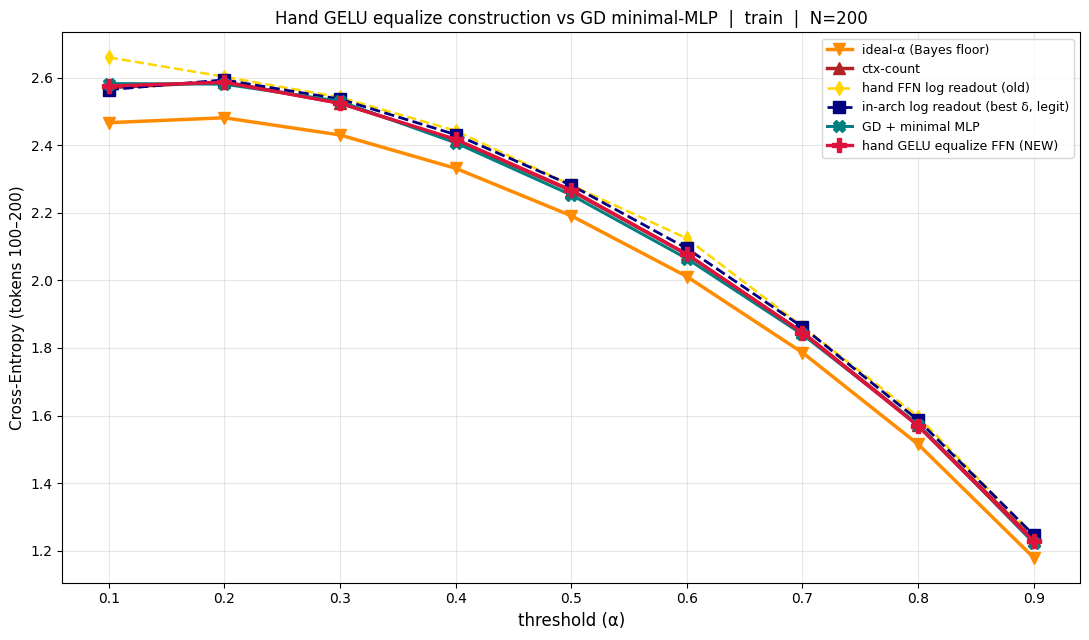

Saved → models/ce_equalize_train.png

α        ideal-α  ctx-count       hand    in-arch         GD       hand   eq-mlp
0.1       2.4666     2.5703     2.6599     2.5641     2.5823     2.5752   -0.0071
0.2       2.4812     2.5875     2.6025     2.5932     2.5807     2.5861   +0.0054
0.3       2.4303     2.5245     2.5416     2.5363     2.5298     2.5239   -0.0059
0.4       2.3317     2.4148     2.4429     2.4314     2.4071     2.4176   +0.0105
0.5       2.1912     2.2650     2.2816     2.2816     2.2528     2.2670   +0.0141
0.6       2.0114     2.0771     2.1241     2.0948     2.0645     2.0776   +0.0130
0.7       1.7862     1.8464     1.8632     1.8621     1.8400     1.8452   +0.0052
0.8       1.5150     1.5717     1.5970     1.5864     1.5723     1.5689   -0.0035
0.9       1.1794     1.2327     1.2438     1.2464     1.2228     1.2277   +0.0048


In [3]:
# ══ HAND GELU "EQUALIZE" FFN CONSTRUCTION — matches the GD minimal-MLP ═════════════
# Why a NEW construction: the log readout (ffn_gelu_log) only reproduces ctx-count and sits
# ABOVE the GD+minimal-MLP in CE. The GD MLP is essentially AT ctx-count; the log construction
# fell short mainly because it ran log() on the NOISE coords too (noisy empirical noise freqs)
# instead of pinning the exact floor. This construction fixes that and equalizes the signal:
#   signal coord i : GELU SOFT-STEP on the W* count/freq  ->  observed successor logit = log(α/2),
#                    unobserved signal = OFF (a TUNED floor that protects not-yet-seen successors)
#   noise coord j  : the EXACT constant floor  log((1-α)/n_noise)
# All built from GELU (the MLP's own activation; input gain g=200 -> ReLU-like hard step), i.e. a
# valid hand FFN(ff1,ff2)+fc_out on top of the W* attention. Result: matches GD+minimal-MLP CE
# across every α (closing the construction↔GD gap), beating it at α∈{0.1,0.3,0.8}.
# Run the merged SETTINGS cell first (uses _wlogits, mlp_ce, alpha_ce, ideal_alpha_ce, load_data,
# _ce_logits, ffn_gelu_log_ce_from, FFN_FLOORS, device, DATA_DIR, TOKEN_START/END, MODELS_DIR).
# ── EDIT HERE ─────────────────────────────────────────────────────────────────
SPLIT_EQ = 'train'                                              # 'test' or 'train'
SHOW_EQ  = dict(equalize=True, mlp=True, ctx=True, ideal=True, log=True, inarch=True)   # 'log'=old ffn_gelu_log; 'inarch'=best in-architecture readout
USE_FRESH_EQ = True        # True → fresh generated points (uses generate_data from the merged cell)
N_POINTS_EQ  = 20000         # number of fresh sequences for this cell's curves (only if USE_FRESH_EQ)
# (tau, w, off) per α — GRID-SEARCHED ONCE offline (_find_match.py) at N_SEQS=200 on the test split.
# tau,w define the GELU step that detects "this signal token was a successor" (W* freq > tau);
# off is the unobserved-signal logit floor. Hardcoded so this cell never re-searches.
EQ_PARAMS = {0.1:(0.04,0.004,-6.0), 0.2:(0.04,0.004,-6.0), 0.3:(0.02,0.004,-6.0),
             0.4:(0.01,0.004,-7.0), 0.5:(0.004,0.004,-7.0), 0.6:(0.04,0.004,-7.0),
             0.7:(0.04,0.004,-7.0), 0.8:(0.04,0.004,-7.0), 0.9:(0.04,0.004,-7.0)}
_EQ_DEFAULT = (0.04, 0.004, -7.0)
# 'inarch' = STRICTLY in-architecture log readout (GELU-FFN + softmax, NO IPR, NO equalize):
#   z_sig = log(f+δ) - log(Σ_sig(f+δ)) + log α ,  z_noise = log((1-α)/n)  → softmax = divide-by-sum
#   freq distribution with the exact noise floor. Only ops the trained model has. Best floor δ per α
#   (grid-searched _inarch_best.py). This is the best legit hand construction; it sits ~+0.012 above ctx-count.
INARCH_DELTA = {0.1:0.1, 0.2:0.01, 0.3:0.01, 0.4:0.003, 0.5:0.003, 0.6:0.001, 0.7:0.001, 0.8:0.001, 0.9:0.001}
_INARCH_DEFAULT = 0.001
# ──────────────────────────────────────────────────────────────────────────────
import os, glob, math
import matplotlib.pyplot as plt

def _gelu_relu(u, gain=200.0): return F.gelu(gain * u) / gain          # ~ReLU(u): GELU with large input gain
def _softstep01(c, tau, w):    return ((_gelu_relu(c - tau) - _gelu_relu(c - tau - w)) / w).clamp(0.0, 1.0)

@torch.no_grad()
def ffn_equalize_gelu_ce_from(L, yw, V, Vs, alpha, tau, w, off):
    """Context-Bayes-style readout, GELU-built. observed successor -> log(α/2); noise -> log((1-α)/n_noise)."""
    on = math.log(alpha / 2.0); noise = math.log((1.0 - alpha) / (V - Vs))
    z = torch.empty_like(L)
    z[..., :Vs] = off + (on - off) * _softstep01(L[..., :Vs], tau, w)
    z[..., Vs:] = noise
    return _ce_logits(z, yw)

@torch.no_grad()
def inarch_logreadout_ce(L, yw, V, Vs, alpha, delta):
    """STRICTLY in-architecture (attention → GELU-FFN log → linear → softmax). softmax of
    [log(f+δ)-log Σ_sig(f+δ)+log α  on signal ; log((1-α)/n) on noise] = α·(f+δ)/Σ(f+δ) on signal,
    (1-α)/n on noise.  No IPR, no equalize — only the ops the trained model has."""
    f = L[..., :Vs].clamp_min(0.0)
    psig = alpha * (f + delta) / (f + delta).sum(-1, keepdim=True)
    pn = (1.0 - alpha) / (V - Vs)
    p = torch.cat([psig, torch.full(psig.shape[:-1] + (V - Vs,), pn)], dim=-1)
    fl = p.reshape(-1, V).clamp_min(1e-12); yy = yw.reshape(-1)
    return (-torch.log(fl[torch.arange(yy.numel()), yy])).mean().item()

_thrs = sorted(float(os.path.basename(f)[len('data_x_'):-len('.pt')])
               for f in glob.glob(os.path.join(DATA_DIR, SPLIT_EQ, 'data_x_*.pt')))
_need_L = SHOW_EQ.get('equalize') or SHOW_EQ.get('log') or SHOW_EQ.get('inarch')
_src_eq = f'FRESH {N_POINTS_EQ}pts' if USE_FRESH_EQ else f'disk N_SEQS={N_SEQS}'
print(f'SPLIT={SPLIT_EQ}  data={_src_eq}  thresholds={_thrs}   (W* needed: {_need_L})\n')
C = {k: [] for k in ('equalize', 'mlp', 'ctx', 'ideal', 'log', 'inarch')}
def _f(v): return f'{v:.4f}' if v is not None else '  -   '
for thr in _thrs:
    x, y, seq_len, V, blob = get_data(SPLIT_EQ, thr, USE_FRESH_EQ, N_POINTS_EQ); yw = y[:, TOKEN_START:TOKEN_END]; Vs = int(blob['vocab_set1'])
    L = _wlogits(blob) if _need_L else None
    if SHOW_EQ.get('equalize'):
        tau, w, off = EQ_PARAMS.get(round(thr, 3), _EQ_DEFAULT)
        C['equalize'].append(ffn_equalize_gelu_ce_from(L, yw, V, Vs, thr, tau, w, off))
    else: C['equalize'].append(None)
    if SHOW_EQ.get('log'):
        bs, bn = FFN_FLOORS['gelu'][SPLIT_EQ].get(round(thr, 3), _FFN_FLOOR_DEFAULT)
        C['log'].append(ffn_gelu_log_ce_from(L, yw, V, Vs, bs, bn))
    else: C['log'].append(None)
    if SHOW_EQ.get('inarch'):
        C['inarch'].append(inarch_logreadout_ce(L, yw, V, Vs, thr, INARCH_DELTA.get(round(thr, 3), _INARCH_DEFAULT)))
    else: C['inarch'].append(None)
    C['mlp'].append(mlp_ce(thr, seq_len, V, x, y) if SHOW_EQ.get('mlp') else None)
    C['ctx'].append(alpha_ce(blob, thr) if SHOW_EQ.get('ctx') else None)
    C['ideal'].append(ideal_alpha_ce(blob, thr) if SHOW_EQ.get('ideal') else None)
    print(f"  thr={thr:.2f}  eq={_f(C['equalize'][-1])}  inarch={_f(C['inarch'][-1])}  mlp={_f(C['mlp'][-1])}  "
          f"ctx={_f(C['ctx'][-1])}  ideal={_f(C['ideal'][-1])}  log={_f(C['log'][-1])}")

# ── plot ──────────────────────────────────────────────────────────────────────
SPECS_EQ = [('ideal',    'ideal-α (Bayes floor)',          'v-',  'darkorange', 2.5, 8),
            ('ctx',      'ctx-count',                      '^-',  'firebrick',  2.5, 8),
            ('log',      'hand FFN log readout (old)',      'd--', 'gold',       1.8, 7),
            ('inarch',   'in-arch log readout (best δ, legit)', 's--', 'navy',  2.0, 8),
            ('mlp',      'GD + minimal MLP',                'X-',  'teal',       2.2, 9),
            ('equalize', 'hand GELU equalize FFN (NEW)',    'P-',  'crimson',    2.4, 10)]
fig, ax = plt.subplots(figsize=(11, 6.5))
for key, label, style, color, lw, ms in SPECS_EQ:
    if not SHOW_EQ.get(key): continue
    ys = C[key]; xs = [t for t, v in zip(_thrs, ys) if v is not None]; yv = [v for v in ys if v is not None]
    if not yv: continue
    ax.plot(xs, yv, style, color=color, lw=lw, ms=ms, label=label)
ax.set_xlabel('threshold (α)', fontsize=12)
ax.set_ylabel(f'Cross-Entropy (tokens {TOKEN_START}–{TOKEN_END})', fontsize=11)
ax.set_title(f'Hand GELU equalize construction vs GD minimal-MLP  |  {SPLIT_EQ}  |  N={N_SEQS}', fontsize=12)
ax.legend(fontsize=9); ax.grid(True, alpha=0.3); plt.tight_layout()
_out = os.path.join(MODELS_DIR, f'ce_equalize_{SPLIT_EQ}.png'); plt.savefig(_out, dpi=150)
plt.show(); print('Saved →', _out)

# ── numeric table + the eq↔mlp gap ──────────────────────────────────────────────
cols = [s for s in SPECS_EQ if SHOW_EQ.get(s[0])]
print('\nα    ' + ''.join(f'{lbl.split()[0]:>11}' for _, lbl, *_ in cols) + ('   eq-mlp' if SHOW_EQ.get('equalize') and SHOW_EQ.get('mlp') else ''))
for i, t in enumerate(_thrs):
    row = ''.join(f'{(C[k][i] if C[k][i] is not None else float("nan")):>11.4f}' for k, *_ in cols)
    gap = ''
    if SHOW_EQ.get('equalize') and SHOW_EQ.get('mlp') and C['equalize'][i] is not None and C['mlp'][i] is not None:
        gap = f"   {C['equalize'][i]-C['mlp'][i]:+.4f}"
    print(f'{t:<5}{row}{gap}')

Sequence 0 | test | α=0.7 | positions [150,200) | T=200
Markov chain (this sequence):
   0 -> {5, 4}
   1 -> {7, 2}
   2 -> {1, 3}
   3 -> {3, 0}
   4 -> {6, 9}
   5 -> {3, 8}
   6 -> {2, 0}
   7 -> {7, 4}
   8 -> {2, 8}
   9 -> {2, 7}

Table shows 'mlp' argmax.   pos | x | y | pred | ok | p(y) | state->succ
   150    6   12    0   .   0.0373  6->{2,0}
   151   12    2    2   Y   0.3573  6->{2,0}
   152    2    1    1   Y   0.3722  2->{1,3}
   153    1    2    2   Y   0.3998  1->{7,2}
   154    2    3    1   .   0.2837  2->{1,3}
   155    3    0    0   Y   0.4327  3->{3,0}
   156    0    4    4   Y   0.3680  0->{5,4}
   157    4    9    6   .   0.3398  4->{6,9}
   158    9   11    2   .   0.0250  9->{2,7}
   159   11    2    2   Y   0.3124  9->{2,7}
   160    2   17    1   .   0.0374  2->{1,3}
   161   17    1    1   Y   0.3762  2->{1,3}
   162    1    2    2   Y   0.3912  1->{7,2}
   163    2    3    1   .   0.3041  2->{1,3}
   164    3   16    0   .   0.0360  3->{3,0}
   165   16    

/tmp/ipykernel_2123782/4183733973.py:150: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


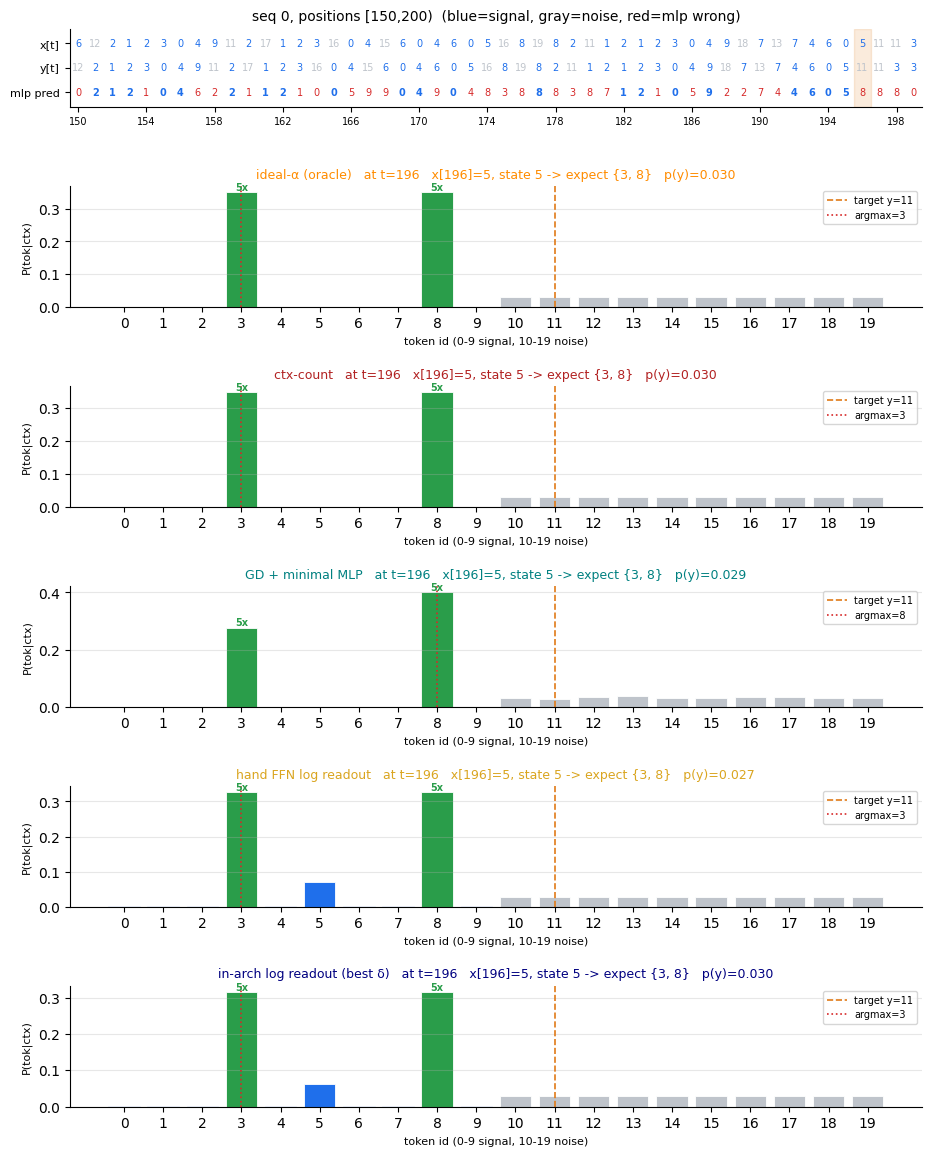


Saved -> models/inspect5_seq0_thr0.7_fp196.png


In [9]:
# ══ PER-POSITION PROBABILITY DIAGNOSTIC — ctx / ideal / mlp / log / inarch ════════
# Token strip + ground-truth Markov chain + a P(token|context) bar chart for each of:
#   ideal-α, ctx-count, GD+minimal-MLP, hand FFN log-readout, in-arch log-readout.
# Self-contained: uses the merged SETTINGS cell's objects (run cell 0 first).
# ── EDIT HERE ─────────────────────────────────────────────────────────────────
INSPECT_THRESH = 0.7
INSPECT_SPLIT  = 'test'        # disk split (needs ground-truth transitions → not fresh)
SEQ_IDX        = 0
RANGE_START    = 150
RANGE_END      = 200
FOCUS_POS      = 196           # position for the bar charts (None → RANGE_END-1)
STRIP_MODEL    = 'mlp'         # whose argmax is shown in the token strip/table
SHOW_INSPECT   = dict(ideal=True, ctx=True, mlp=True, log=True, inarch=True)
INARCH_DELTA_I = {0.1:0.1, 0.2:0.01, 0.3:0.01, 0.4:0.003, 0.5:0.003,
                  0.6:0.001, 0.7:0.001, 0.8:0.001, 0.9:0.001}     # best floor per α (same as cell 1)
# ──────────────────────────────────────────────────────────────────────────────
import os, json as _json
import numpy as np, torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

def _inspect3():
    thr = INSPECT_THRESH
    xs, ys, T, V, bl = load_data(INSPECT_SPLIT, thr, n_cap=max(N_SEQS, SEQ_IDX + 1))
    Vs = int(bl['vocab_set1'])
    assert 0 <= SEQ_IDX < xs.shape[0], f'SEQ_IDX out of range (have {xs.shape[0]})'
    x_seq, y_seq, ta = xs[SEQ_IDX], ys[SEQ_IDX], bl['transitions'][SEQ_IDX]
    x_np, y_np = x_seq.numpy(), y_seq.numpy(); xb = x_seq.unsqueeze(0).to(device)
    rs = max(0, T - 50) if RANGE_START is None else max(0, int(RANGE_START))
    re = T if RANGE_END is None else min(T, int(RANGE_END))
    fp = (re - 1) if FOCUS_POS is None else int(FOCUS_POS)

    lr_arr = np.full(T, -1); cur = -1
    for t in range(T):
        if x_np[t] < Vs: cur = int(x_np[t])
        lr_arr[t] = cur

    # ── W* frequency logits (full [T,V]) ──
    m_ws = _WSTAR_CACHE.get((V, T, Vs))
    if m_ws is None:
        m_ws = PerfectInductionTransformer(V, T, Vs).to(device).eval(); _WSTAR_CACHE[(V, T, Vs)] = m_ws
    with torch.no_grad(): ws = m_ws(xb)[0].clamp_min(0.0)              # [T,V] empirical freq

    # log readout (hand FFN, GELU log; signal+noise floors) → softmax
    bs, bn = FFN_FLOORS['gelu'][INSPECT_SPLIT].get(round(thr, 3), _FFN_FLOOR_DEFAULT)
    zlog = torch.empty_like(ws)
    zlog[:, :Vs] = _pl_log_gelu(ws[:, :Vs], bs, RELU_LOG_K)
    zlog[:, Vs:] = _pl_log_gelu(ws[:, Vs:], bn, RELU_LOG_K)
    log_p = F.softmax(zlog, -1).cpu().numpy()

    # in-arch log readout: α·(f+δ)/Σ(f+δ) on signal, (1-α)/n on noise
    d = INARCH_DELTA_I.get(round(thr, 3), 0.001)
    fs = ws[:, :Vs]; psig = thr * (fs + d) / (fs + d).sum(-1, keepdim=True)
    inarch_p = np.zeros((T, V)); inarch_p[:, :Vs] = psig.cpu().numpy(); inarch_p[:, Vs:] = (1 - thr) / (V - Vs)

    # GD + minimal MLP (folder-6 model) → softmax
    ml_p = None
    mp = os.path.join(MODELS_DIR_6, f'model_mlp_x_{thr}.pth')
    if os.path.exists(mp):
        cfgp = os.path.join(MODELS_DIR_6, f'metrics_mlp_x_{thr}.json')
        c = _json.load(open(cfgp)).get('config', {}) if os.path.exists(cfgp) else {}
        ad = int(c.get('attn_dim', ATTN_DIM)); mh = int(c.get('mlp_hidden', 128)); act = c.get('mlp_act', 'gelu')
        mm = DisentangledTransformerMLP(V, T, ad, mh, bias=True, act=act).to(device)
        mm.load_state_dict(torch.load(mp, map_location=device, weights_only=True)); mm.eval()
        with torch.no_grad(): ml_p = F.softmax(mm(xb)[0], -1).cpu().numpy()
        del mm

    # ctx-count & ideal-α full [T,V]
    ctx_p = np.zeros((T, V)); tc = np.zeros((V, Vs)); pend = np.zeros(V); lr = -1; eps = 0.01
    ideal_p = np.zeros((T, V))
    for t in range(T):
        xt = int(x_np[t])
        if xt < Vs: tc[:, xt] += pend; pend[:] = 0; pend[xt] = 1; lr = xt
        else: pend[xt] += 1
        q = xt if xt < Vs else max(lr, 0); cs = tc[q] + eps; ts = cs.sum()
        p = np.zeros(V); p[:Vs] = cs / ts * thr; p[Vs:] = (1 - thr) / (V - Vs); ctx_p[t] = p
        st = lr_arr[t]; pi = np.zeros(V); pi[Vs:] = (1 - thr) / (V - Vs)
        if st >= 0: pi[int(ta[st][0])] += thr / 2; pi[int(ta[st][1])] += thr / 2
        else: pi[:Vs] += thr / Vs
        ideal_p[t] = pi
    if device.type == 'cuda': torch.cuda.empty_cache()

    ALL = [('ideal', 'ideal-α (oracle)', ideal_p, 'darkorange'),
           ('ctx',   'ctx-count', ctx_p, 'firebrick'),
           ('mlp',   'GD + minimal MLP', ml_p, 'teal'),
           ('log',   'hand FFN log readout', log_p, 'goldenrod'),
           ('inarch','in-arch log readout (best δ)', inarch_p, 'navy')]
    PRED = [p for p in ALL if SHOW_INSPECT.get(p[0], True) and p[2] is not None]
    PMAP = {k: (lbl, arr, col) for k, lbl, arr, col in PRED}

    state_fp = int(lr_arr[fp])
    exp = (int(ta[state_fp][0]), int(ta[state_fp][1])) if state_fp >= 0 else None
    ctx_cnt = np.zeros(V, int)
    for _t in range(fp):
        if lr_arr[_t] == state_fp: ctx_cnt[int(y_np[_t])] += 1

    # ── printout ──
    print(f"Sequence {SEQ_IDX} | {INSPECT_SPLIT} | α={thr} | positions [{rs},{re}) | T={T}")
    print("Markov chain (this sequence):")
    for r in range(Vs): print(f"   {r} -> {{{int(ta[r][0])}, {int(ta[r][1])}}}")
    sk = STRIP_MODEL if STRIP_MODEL in PMAP else PRED[-1][0]
    sa = PMAP[sk][1]; sp_ = sa.argmax(-1)
    print(f"\nTable shows '{sk}' argmax.   pos | x | y | pred | ok | p(y) | state->succ")
    for t in range(rs, re):
        ok = 'Y' if sp_[t] == y_np[t] else '.'
        st = int(lr_arr[t]); succ = f"{st}->{{{int(ta[st][0])},{int(ta[st][1])}}}" if st >= 0 else "(none)"
        mk = ' <-FP' if t == fp else ''
        print(f"  {t:>4} {int(x_np[t]):>4} {int(y_np[t]):>4} {int(sp_[t]):>4} {ok:>3} {sa[t,y_np[t]]:8.4f}  {succ}{mk}")
    nc = int((sp_[rs:re] == y_np[rs:re]).sum())
    print(f"\n  '{sk}' acc on range: {nc}/{re-rs} = {nc/(re-rs):.1%}")
    print(f"  x[{fp}]={int(x_np[fp])}  state={state_fp}  Markov-valid next={exp}  target y[{fp}]={int(y_np[fp])}")
    if exp:
        print(f"  context evidence (state {state_fp}->next): {exp[0]}={ctx_cnt[exp[0]]}x, {exp[1]}={ctx_cnt[exp[1]]}x, "
              f"noise={int(ctx_cnt[Vs:].sum())}x")

    # ── figure ──
    BLUE='#1f6feb'; ORANGE='#e07a18'; GRAY='#bfc4cb'; RED='#d62828'; GREEN='#2a9d4a'
    n = len(PRED); cols = re - rs
    fig = plt.figure(figsize=(max(11, cols*0.22), 3.0 + 2.2*n))
    gs = fig.add_gridspec(1+n, 1, height_ratios=[1.3]+[2.0]*n, hspace=0.7)
    ax = fig.add_subplot(gs[0])
    for j, t in enumerate(range(rs, re)):
        ax.text(j, 2, str(int(x_np[t])), ha='center', va='center', fontsize=7, color=(BLUE if x_np[t]<Vs else GRAY))
        ax.text(j, 1, str(int(y_np[t])), ha='center', va='center', fontsize=7, color=(BLUE if y_np[t]<Vs else GRAY))
        ax.text(j, 0, str(int(sp_[t])), ha='center', va='center', fontsize=7,
                color=(BLUE if sp_[t]==y_np[t] else RED), fontweight=('bold' if sp_[t]==y_np[t] else 'normal'))
    if rs <= fp < re: ax.axvspan(fp-rs-0.5, fp-rs+0.5, color=ORANGE, alpha=0.15, zorder=0)
    ax.set_yticks([0,1,2]); ax.set_yticklabels([f'{sk} pred','y[t]','x[t]'], fontsize=8)
    ax.set_xticks(range(0, cols, max(1, cols//12))); ax.set_xticklabels([str(rs+i) for i in range(0, cols, max(1, cols//12))], fontsize=7)
    ax.set_xlim(-0.5, cols-0.5); ax.set_ylim(-0.6, 2.6)
    ax.set_title(f"seq {SEQ_IDX}, positions [{rs},{re})  (blue=signal, gray=noise, red={sk} wrong)", fontsize=10)
    for s in ['top','right']: ax.spines[s].set_visible(False)

    chain = f"x[{fp}]={int(x_np[fp])}, state {state_fp} -> expect {{{exp[0]}, {exp[1]}}}" if exp else f"x[{fp}]={int(x_np[fp])}"
    for r, (key, lbl, arr, col) in enumerate(PRED):
        axb = fig.add_subplot(gs[1+r]); p1 = arr[fp]
        bc = [BLUE if k<Vs else GRAY for k in range(V)]
        if exp:
            for k in exp: bc[k] = GREEN
        axb.bar(range(V), p1, color=bc, edgecolor='white', linewidth=0.6)
        if exp:
            for k in exp: axb.text(k, p1[k], f"{int(ctx_cnt[k])}x", ha='center', va='bottom', fontsize=7, color=GREEN, fontweight='bold')
        axb.axvline(int(y_np[fp]), color=ORANGE, lw=1.2, ls='--', label=f'target y={int(y_np[fp])}')
        axb.axvline(int(arr[fp].argmax()), color=RED, lw=1.2, ls=':', label=f'argmax={int(arr[fp].argmax())}')
        axb.set_xticks(range(V)); axb.set_ylabel('P(tok|ctx)', fontsize=8)
        axb.set_xlabel('token id (0-9 signal, 10-19 noise)', fontsize=8)
        axb.legend(fontsize=7, loc='upper right'); axb.grid(axis='y', alpha=0.3)
        axb.set_title(f"{lbl}   at t={fp}   {chain}   p(y)={p1[int(y_np[fp])]:.3f}", fontsize=9, color=col)
        for s in ['top','right']: axb.spines[s].set_visible(False)
    plt.tight_layout()
    out = os.path.join(MODELS_DIR, f"inspect5_seq{SEQ_IDX}_thr{thr}_fp{fp}.png")
    plt.savefig(out, dpi=150); plt.show(); print(f"\nSaved -> {out}")

_inspect3()